In [61]:
import pandas as pd
from pathlib import Path

# Load the original dataset
file_path = Path("../data/raw/yield_df.csv")
df = pd.read_csv(file_path)

# Inspect the dataset
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Check available crop names for India
india = df[df["Area"].str.strip() == "India"]

print("\nAvailable crops in India:")
print(sorted(india["Item"].unique()))

Dataset shape: (28242, 8)
Columns: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

Available crops in India:
['Cassava', 'Maize', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat']


In [62]:
# Crops specified in the research paper
target_crops = [
    "Rice, paddy",
    "Wheat",
    "Potatoes",
    "Soybeans",
    "Sweet potatoes",
    "Sorghum"
]
# Filter India, selected crops, and study period
india_df = df[
    (df["Area"].str.strip() == "India") &
    (df["Item"].isin(target_crops)) &
    (df["Year"].between(1990, 2013))
].copy()

# Remove the unnecessary index column, if present
india_df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)

# Display verification information
print("India dataset shape:", india_df.shape)
print("\nRecords per crop:")
print(india_df["Item"].value_counts().sort_index())

print("\nYear range:")
print(india_df["Year"].min(), "-", india_df["Year"].max())

print("\nMissing values:")
print(india_df.isnull().sum())

India dataset shape: (3036, 7)

Records per crop:
Item
Potatoes          506
Rice, paddy       506
Sorghum           506
Soybeans          506
Sweet potatoes    506
Wheat             506
Name: count, dtype: int64

Year range:
1990 - 2013

Missing values:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64


phase 3


In [63]:
import pandas as pd
from pathlib import Path

# Load the original dataset
file_path = Path("../data/raw/yield_df.csv")
df = pd.read_csv(file_path)

# Define the six target crops using the exact CSV labels
target_crops = [
    "Rice, paddy",
    "Wheat",
    "Potatoes",
    "Soybeans",
    "Sweet potatoes",
    "Sorghum"
]

# Filter the dataset
india_df = df[
    (df["Area"].str.strip() == "India") &
    (df["Item"].isin(target_crops)) &
    (df["Year"].between(1990, 2013))
].copy()

# Remove the unnecessary index column
india_df.drop(
    columns=["Unnamed: 0"],
    errors="ignore",
    inplace=True
)

print("Filtered dataset shape:", india_df.shape)
print("\nFirst five records:")

print(india_df.head())
print("updated dataset: ",india_df.shape)
print("original dataset:",df.shape)

Filtered dataset shape: (3036, 7)

First five records:
        Area      Item  Year  hg/ha_yield  average_rain_fall_mm_per_year  \
10546  India  Potatoes  1990       157136                         1083.0   
10547  India  Potatoes  1990       157136                         1083.0   
10548  India  Potatoes  1990       157136                         1083.0   
10549  India  Potatoes  1990       157136                         1083.0   
10550  India  Potatoes  1990       157136                         1083.0   

       pesticides_tonnes  avg_temp  
10546            75000.0     25.58  
10547            75000.0     26.88  
10548            75000.0     25.79  
10549            75000.0     24.10  
10550            75000.0     25.25  
updated dataset:  (3036, 7)
original dataset: (28242, 8)


what we check:

Records per crop: Shows how many observations are available for each crop.

Unique crops: Should be six if all target crops are represented.

Minimum and maximum years: Should be within 1990–2013.

Available years: Helps identify missing years in the filtered dataset.

In [64]:
print("Records per crop:")
print(india_df["Item"].value_counts().sort_index())

print("\nUnique crops:", india_df["Item"].nunique())

print("\nYear range:")
print("Minimum year:", india_df["Year"].min())
print("Maximum year:", india_df["Year"].max())


Records per crop:
Item
Potatoes          506
Rice, paddy       506
Sorghum           506
Soybeans          506
Sweet potatoes    506
Wheat             506
Name: count, dtype: int64

Unique crops: 6

Year range:
Minimum year: 1990
Maximum year: 2013


In [65]:
print("Missing values per column:")
print(india_df.isnull().sum())

print("\nTotal missing values:", india_df.isnull().sum().sum())

Missing values per column:
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Total missing values: 0


In [66]:
print(
    "Exact duplicate rows:",
    india_df.duplicated().sum()
)
duplicate_crop_year = india_df.duplicated(
    subset=["Area", "Item", "Year"],
    keep=False
)

print(
    "Records with repeated crop-year combinations:",
    duplicate_crop_year.sum()
)

if duplicate_crop_year.any():
    print(
        india_df.loc[
            duplicate_crop_year,
            ["Area", "Item", "Year"]
        ].sort_values(["Item", "Year"])
    )

Exact duplicate rows: 498
Records with repeated crop-year combinations: 3036
        Area      Item  Year
10546  India  Potatoes  1990
10547  India  Potatoes  1990
10548  India  Potatoes  1990
10549  India  Potatoes  1990
10550  India  Potatoes  1990
...      ...       ...   ...
14545  India     Wheat  2013
14546  India     Wheat  2013
14547  India     Wheat  2013
14548  India     Wheat  2013
14549  India     Wheat  2013

[3036 rows x 3 columns]


In [67]:
print("column names:", india_df.columns.tolist())
print("data types:", india_df.dtypes)
print("statistics summary:", india_df.describe())
print("unique values per column:", sorted(india_df["Item"].unique()))

column names: ['Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
data types: Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object
statistics summary:               Year    hg/ha_yield  average_rain_fall_mm_per_year  \
count  3036.000000    3036.000000                         3036.0   
mean   2001.434783   57589.231884                         1083.0   
std       7.065010   62324.888885                            0.0   
min    1990.000000    6553.000000                         1083.0   
25%    1995.000000   10319.000000                         1083.0   
50%    2001.000000   28124.000000                         1083.0   
75%    2008.000000   86907.000000                         1083.0   
max

In [68]:

our_row_count = len(india_df)

print("Our filtered dataset row count:", our_row_count)
print("Reported paper row count in our working notes: 4048")

if our_row_count == 4048:
    print("The row counts match numerically.")
else:
    print("The row counts differ. We need to investigate why.")



Our filtered dataset row count: 3036
Reported paper row count in our working notes: 4048
The row counts differ. We need to investigate why.


Investigate the repeated records

In [69]:
# Count unique crop-year combinations
print(
    "Unique crop-year combinations:",
    india_df[["Item", "Year"]].drop_duplicates().shape[0]
)

# Inspect one crop-year group
wheat_1990 = india_df[
    (india_df["Item"] == "Wheat") &
    (india_df["Year"] == 1990)
]

display(wheat_1990.head(10))

Unique crop-year combinations: 138


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
10656,India,Wheat,1990,21211,1083.0,75000.0,25.58
10657,India,Wheat,1990,21211,1083.0,75000.0,26.88
10658,India,Wheat,1990,21211,1083.0,75000.0,25.79
10659,India,Wheat,1990,21211,1083.0,75000.0,24.10
10660,India,Wheat,1990,21211,1083.0,75000.0,25.25
10661,India,Wheat,1990,21211,1083.0,75000.0,25.44
10662,India,Wheat,1990,21211,1083.0,75000.0,25.54
10663,India,Wheat,1990,21211,1083.0,75000.0,26.36
10664,India,Wheat,1990,21211,1083.0,75000.0,26.91
10665,India,Wheat,1990,21211,1083.0,75000.0,25.16


checking


In [70]:

# Get the actual crops and years in our intended scope
expected_crops = [
    "Potatoes",
    "Rice, paddy",
    "Sorghum",
    "Soybeans",
    "Sweet potatoes",
    "Wheat"
]

expected_years = list(range(1990, 2014))

# Generate all expected crop-year combinations
expected_combinations = pd.MultiIndex.from_product(
    [expected_crops, expected_years],
    names=["Item", "Year"]
).to_frame(index=False)

# Get combinations that actually exist
actual_combinations = india_df[["Item", "Year"]].drop_duplicates()

# Find combinations missing from the dataset
missing_combinations = (
    expected_combinations
    .merge(
        actual_combinations,
        on=["Item", "Year"],
        how="left",
        indicator=True
    )
    .query('_merge == "left_only"')
    .drop(columns="_merge")
)

print("Expected combinations:", len(expected_combinations))
print("Actual combinations:", len(actual_combinations))
print("Missing combinations:", len(missing_combinations))

display(missing_combinations)



Expected combinations: 144
Actual combinations: 138
Missing combinations: 6


,Item,Year
13,Potatoes,2003
37,"Rice, paddy",2003
61,Sorghum,2003
85,Soybeans,2003
109,Sweet potatoes,2003
133,Wheat,2003


In [71]:

temperature_variation = (
    india_df.groupby(["Item", "Year"])
    .agg(
        record_count=("avg_temp", "size"),
        unique_temperatures=("avg_temp", "nunique"),
        unique_yields=("hg/ha_yield", "nunique"),
        unique_rainfall=(
            "average_rain_fall_mm_per_year",
            "nunique"
        ),
        unique_pesticide_values=("pesticides_tonnes", "nunique")
    )
    .reset_index()
)

print("Summary of observations within crop-year groups:")
display(temperature_variation.head(20))

print("\nNumber of unique temperatures per crop-year:")
print(temperature_variation["unique_temperatures"].value_counts().sort_index())

print("\nNumber of crop-year groups with multiple temperatures:")
print((temperature_variation["unique_temperatures"] > 1).sum())

print("\nNumber of crop-year groups with multiple yields:")
print((temperature_variation["unique_yields"] > 1).sum())



Summary of observations within crop-year groups:


,Item,Year,record_count,unique_temperatures,unique_yields,unique_rainfall,unique_pesticide_values
0,Potatoes,1990,22,18,1,1,1
1,Potatoes,1991,22,18,1,1,1
2,Potatoes,1992,22,19,1,1,1
3,Potatoes,1993,22,19,1,1,1
4,Potatoes,1994,22,17,1,1,1
5,Potatoes,1995,22,19,1,1,1
6,Potatoes,1996,22,18,1,1,1
7,Potatoes,1997,22,17,1,1,1
8,Potatoes,1998,22,17,1,1,1
9,Potatoes,1999,22,19,1,1,1



Number of unique temperatures per crop-year:
unique_temperatures
17    24
18    36
19    78
Name: count, dtype: int64

Number of crop-year groups with multiple temperatures:
138

Number of crop-year groups with multiple yields:
0


In [72]:

# Inspect temperature values for one year across all target crops
temperature_1990 = (
    india_df[india_df["Year"] == 1990]
    [["Item", "Year", "avg_temp"]]
    .sort_values(["Item", "avg_temp"])
)

display(temperature_1990.head(40))

print("\nNumber of records in 1990:", len(temperature_1990))
print(
    "Number of unique temperatures in 1990:",
    temperature_1990["avg_temp"].nunique()
)



,Item,Year,avg_temp
10549,Potatoes,1990,24.10
10558,Potatoes,1990,24.10
10564,Potatoes,1990,24.37
10562,Potatoes,1990,24.78
10557,Potatoes,1990,25.12
10555,Potatoes,1990,25.16
10550,Potatoes,1990,25.25
10551,Potatoes,1990,25.44
10561,Potatoes,1990,25.44
10552,Potatoes,1990,25.54



Number of records in 1990: 132
Number of unique temperatures in 1990: 18


verify the aggeration startegy

In [73]:

# Group observations by crop and year
grouped = india_df.groupby(["Area", "Item", "Year"])

# Verify whether yield, rainfall, and pesticide usage
# are constant within each crop-year group
consistency_check = grouped.agg(
    record_count=("avg_temp", "size"),
    unique_yields=("hg/ha_yield", "nunique"),
    unique_rainfall=(
        "average_rain_fall_mm_per_year",
        "nunique"
    ),
    unique_pesticide_values=("pesticides_tonnes", "nunique"),
    unique_temperatures=("avg_temp", "nunique")
)

print("Are yields constant within each group?",
      (consistency_check["unique_yields"] == 1).all())

print("Is rainfall constant within each group?",
      (consistency_check["unique_rainfall"] == 1).all())

print("Is pesticide usage constant within each group?",
      (consistency_check["unique_pesticide_values"] == 1).all())

print("\nGroup consistency summary:")
display(consistency_check.describe())



Are yields constant within each group? True
Is rainfall constant within each group? True
Is pesticide usage constant within each group? True

Group consistency summary:


,record_count,unique_yields,unique_rainfall,unique_pesticide_values,unique_temperatures
count,138.0,138.0,138.0,138.0,138.000000
mean,22.0,1.0,1.0,1.0,18.391304
std,0.0,0.0,0.0,0.0,0.768303
min,22.0,1.0,1.0,1.0,17.000000
25%,22.0,1.0,1.0,1.0,18.000000
50%,22.0,1.0,1.0,1.0,19.000000
75%,22.0,1.0,1.0,1.0,19.000000
max,22.0,1.0,1.0,1.0,19.000000


In [74]:

# Create a separate annual dataset
annual_df = (
    india_df
    .groupby(["Area", "Item", "Year"], as_index=False)
    .agg(
        hg_ha_yield=("hg/ha_yield", "first"),
        average_rain_fall_mm_per_year=(
            "average_rain_fall_mm_per_year",
            "first"
        ),
        pesticides_tonnes=("pesticides_tonnes", "first"),
        avg_temp=("avg_temp", "mean")
    )
)

# Round average temperature to two decimal places
annual_df["avg_temp"] = annual_df["avg_temp"].round(2)

# Sort the dataset
annual_df = annual_df.sort_values(
    ["Item", "Year"]
).reset_index(drop=True)

print("Original filtered rows:", len(india_df))
print("Annual dataset rows:", len(annual_df))

print("\nDataset shape:", annual_df.shape)
print("\nRecords per crop:")
print(annual_df["Item"].value_counts().sort_index())

print("\nFirst five annual records:")
display(annual_df.head())



Original filtered rows: 3036
Annual dataset rows: 138

Dataset shape: (138, 7)

Records per crop:
Item
Potatoes          23
Rice, paddy       23
Sorghum           23
Soybeans          23
Sweet potatoes    23
Wheat             23
Name: count, dtype: int64

First five annual records:


,Area,Item,Year,hg_ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,India,Potatoes,1990,157136,1083.0,75000.0,25.60
1,India,Potatoes,1991,162540,1083.0,72133.0,25.75
2,India,Potatoes,1992,160294,1083.0,70791.0,25.72
3,India,Potatoes,1993,149024,1083.0,66388.0,25.92
4,India,Potatoes,1994,166101,1083.0,61357.0,25.72


Validate the Final Annual Dataset

In [75]:
print("Dataset shape:", annual_df.shape)

print("\nMissing values:")
print(annual_df.isnull().sum())

print("\nExact duplicate rows:")
print(annual_df.duplicated().sum())

print("\nRepeated crop-year combinations:")
print(
    annual_df.duplicated(
        subset=["Area", "Item", "Year"]
    ).sum()
)

print("\nUnique crop-year combinations:")
print(
    annual_df[["Item", "Year"]]
    .drop_duplicates()
    .shape[0]
)

print("\nYear range:")
print(annual_df["Year"].min(), "to", annual_df["Year"].max())

print("\nRecords per crop:")
print(annual_df["Item"].value_counts().sort_index())

Dataset shape: (138, 7)

Missing values:
Area                             0
Item                             0
Year                             0
hg_ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

Exact duplicate rows:
0

Repeated crop-year combinations:
0

Unique crop-year combinations:
138

Year range:
1990 to 2013

Records per crop:
Item
Potatoes          23
Rice, paddy       23
Sorghum           23
Soybeans          23
Sweet potatoes    23
Wheat             23
Name: count, dtype: int64


saving the processed dataset

In [76]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "india_crop_yield_annual.csv"

annual_df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("File location:", output_path.resolve())
print("Saved dataset shape:", annual_df.shape)

Dataset saved successfully!
File location: D:\internship\extragard\cropai\data\processed\india_crop_yield_annual.csv
Saved dataset shape: (138, 7)


Phase 4 : EDA

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load the processed dataset
data_path = Path("../data/processed/india_crop_yield_annual.csv")

annual_df = pd.read_csv(data_path)

# Display basic information
print("Dataset shape:", annual_df.shape)

print("\nColumns:")
print(annual_df.columns.tolist())

print("\nFirst five records:")
display(annual_df.head())

Dataset shape: (138, 7)

Columns:
['Area', 'Item', 'Year', 'hg_ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']

First five records:


,Area,Item,Year,hg_ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,India,Potatoes,1990,157136,1083.0,75000.0,25.60
1,India,Potatoes,1991,162540,1083.0,72133.0,25.75
2,India,Potatoes,1992,160294,1083.0,70791.0,25.72
3,India,Potatoes,1993,149024,1083.0,66388.0,25.92
4,India,Potatoes,1994,166101,1083.0,61357.0,25.72


In [78]:
"""statistical summary understanding"""
print("Statistical summary:")
display(annual_df.describe())

print("\nUnique crops:")
print(annual_df["Item"].unique())

print("\nUnique years:")
print(annual_df["Year"].nunique())

print("\nUnique rainfall values:")
print(annual_df["average_rain_fall_mm_per_year"].nunique())

print("\nUnique pesticide values:")
print(annual_df["pesticides_tonnes"].nunique())

print("\nUnique temperature values:")
print(annual_df["avg_temp"].nunique())

Statistical summary:


,Year,hg_ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,138.000000,138.000000,138.0,138.000000,138.000000
mean,2001.434783,57589.231884,1083.0,48459.040000,26.013478
std,7.089580,62541.635862,0.0,15050.128012,0.332615
min,1990.000000,6553.000000,1083.0,14485.330000,25.350000
25%,1995.000000,10343.000000,1083.0,37423.000000,25.770000
50%,2001.000000,28124.000000,1083.0,46195.000000,25.960000
75%,2008.000000,86892.500000,1083.0,61257.000000,26.160000
max,2013.000000,227606.000000,1083.0,75000.000000,26.750000



Unique crops:
['Potatoes' 'Rice, paddy' 'Sorghum' 'Soybeans' 'Sweet potatoes' 'Wheat']

Unique years:
23

Unique rainfall values:
1

Unique pesticide values:
23

Unique temperature values:
21


step 3(phase 4): compare the yield across crops

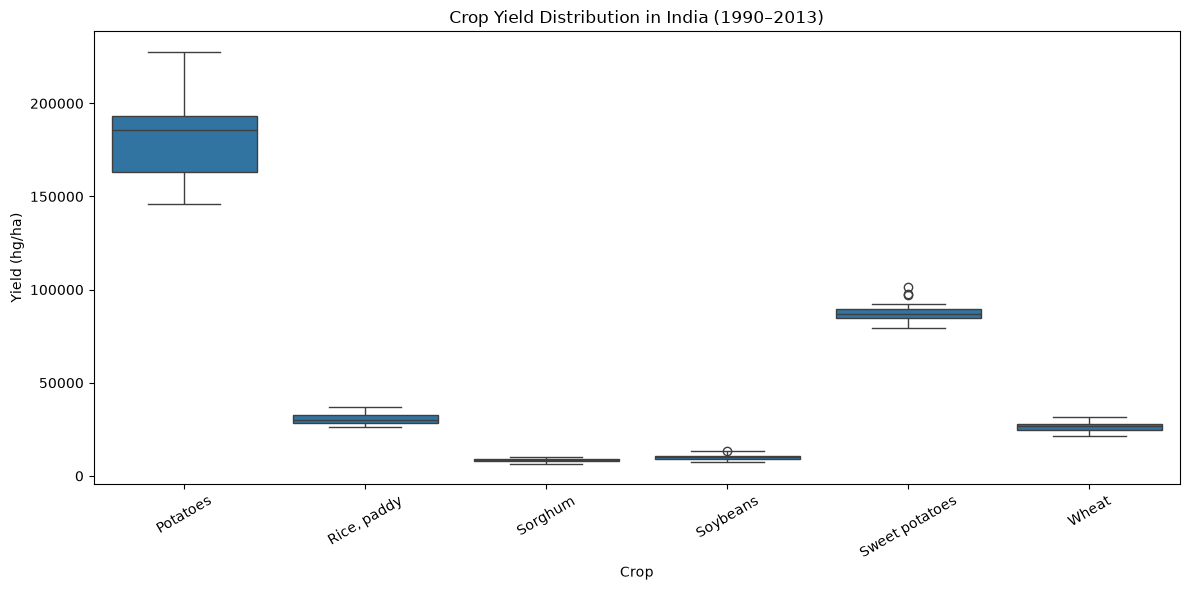

In [79]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=annual_df,
    x="Item",
    y="hg_ha_yield"
)

plt.title("Crop Yield Distribution in India (1990–2013)")
plt.xlabel("Crop")
plt.ylabel("Yield (hg/ha)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

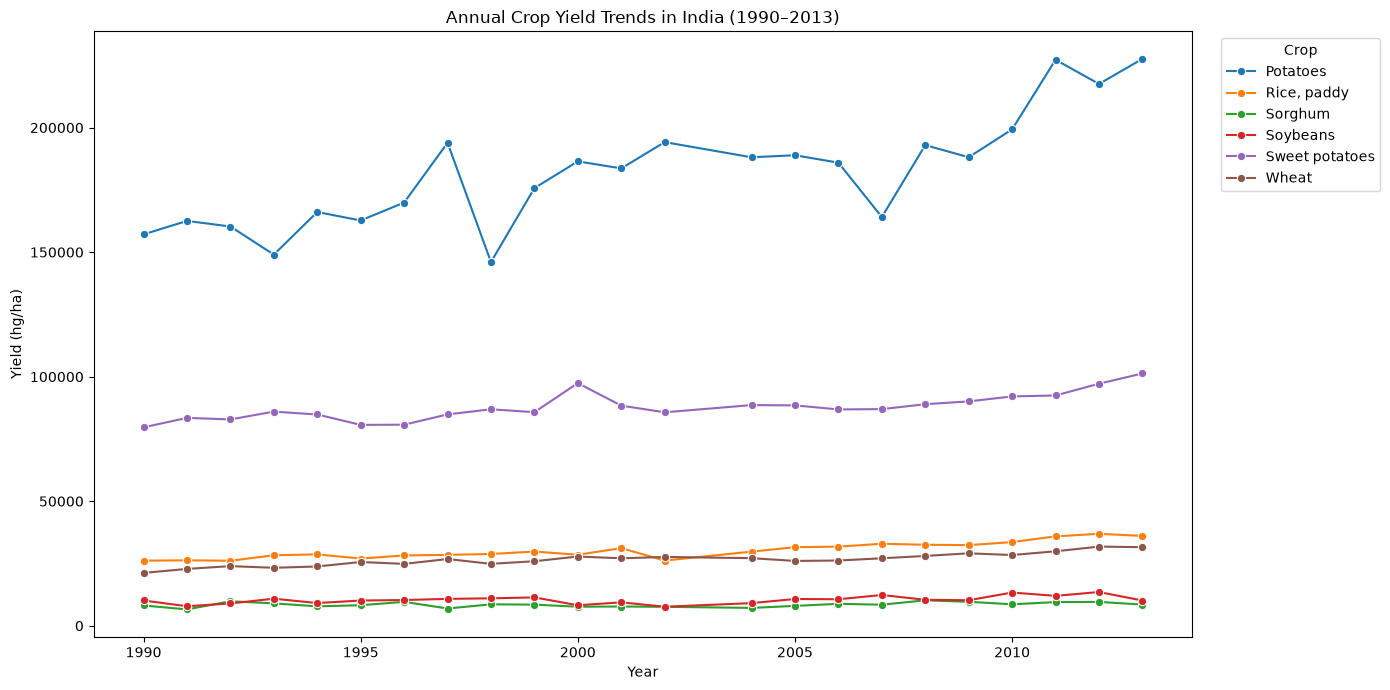

In [80]:
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=annual_df,
    x="Year",
    y="hg_ha_yield",
    hue="Item",
    marker="o"
)

plt.title("Annual Crop Yield Trends in India (1990–2013)")
plt.xlabel("Year")
plt.ylabel("Yield (hg/ha)")
plt.legend(title="Crop", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [81]:
rainfall_summary = (
    annual_df.groupby("Item")["average_rain_fall_mm_per_year"]
    .agg(["min", "max", "nunique", "mean"])
)

display(rainfall_summary)

print(
    "\nTotal unique rainfall values:",
    annual_df["average_rain_fall_mm_per_year"].nunique()
)

,min,max,nunique,mean
Item,,,,
Potatoes,1083.0,1083.0,1,1083.0
"Rice, paddy",1083.0,1083.0,1,1083.0
Sorghum,1083.0,1083.0,1,1083.0
Soybeans,1083.0,1083.0,1,1083.0
Sweet potatoes,1083.0,1083.0,1,1083.0
Wheat,1083.0,1083.0,1,1083.0



Total unique rainfall values: 1


EDA Results: What We Have Learned???

Finding 1: Potato yield is the highest; sorghum yield is the lowest

Finding 2: Crop yields generally increase over time, but not uniformly

Finding 3: Rainfall Cannot Help Distinguish Your Observations

In [82]:
# Examine pesticide usage across crops and years

pesticide_by_year = (
    annual_df
    .groupby("Year")["pesticides_tonnes"]
    .agg(["min", "max", "nunique"])
)

print("Pesticide usage by year:")
display(pesticide_by_year)

print(
    "\nYears where pesticide usage differs across crop records:",
    (pesticide_by_year["nunique"] > 1).sum()
)

print(
    "\nTotal unique pesticide values:",
    annual_df["pesticides_tonnes"].nunique()
)

Pesticide usage by year:


,min,max,nunique
Year,,,
1990,75000.00,75000.00,1
1991,72133.00,72133.00,1
1992,70791.00,70791.00,1
1993,66388.00,66388.00,1
1994,61357.00,61357.00,1
1995,61257.00,61257.00,1
1996,56114.00,56114.00,1
1997,52279.00,52279.00,1
1998,49157.00,49157.00,1



Years where pesticide usage differs across crop records: 0

Total unique pesticide values: 23


final eda step : Correlation Analysis

In [83]:
# Select numerical columns
numeric_df = annual_df[
    [
        "Year",
        "hg_ha_yield",
        "pesticides_tonnes",
        "avg_temp"
    ]
]

# Calculate correlations
correlation_matrix = numeric_df.corr()

print("Correlation matrix:")
display(correlation_matrix.round(3))

Correlation matrix:


,Year,hg_ha_yield,pesticides_tonnes,avg_temp
Year,1.000,0.076,-0.719,0.614
hg_ha_yield,0.076,1.000,-0.038,0.037
pesticides_tonnes,-0.719,-0.038,1.000,-0.461
avg_temp,0.614,0.037,-0.461,1.000


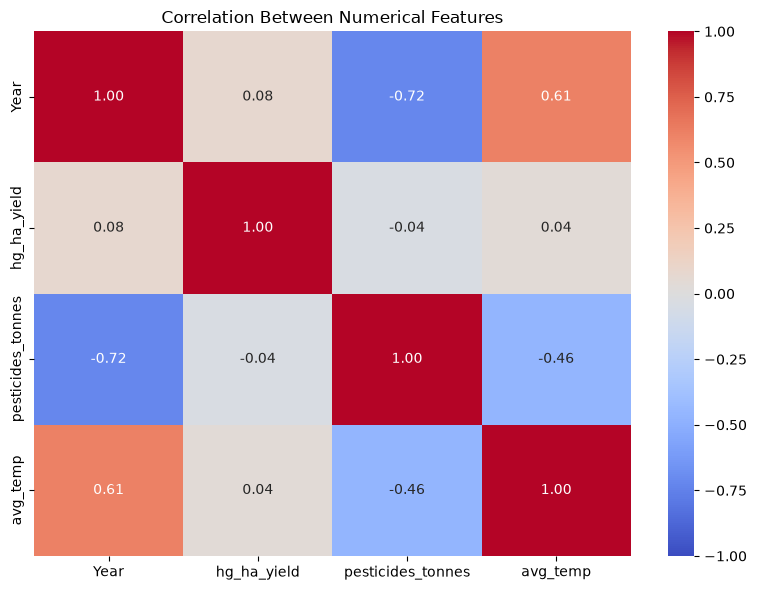

In [84]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

Current findings

The processed dataset contains 138 observations across six crops.

Each crop has 23 observations, covering 1990–2013 except 2003.

Rainfall is constant at 1,083 mm/year and cannot distinguish observations.

Pesticide usage varies by year but is identical across crops within each year.

Crop yields differ substantially between crop types.

Overall numerical correlations with yield are weak.

Temperature and pesticide usage are associated with year, so their independent predictive contributions need careful evaluation.


Phase 5: feature engineering and pre processing

1. Define the prediction problem

        Our objective is:

        Given a crop and information available up to a particular point in time, predict its yield for a future year.

        For example, we want to train a model on earlier observations and evaluate whether it can predict wheat yields for later years.